# Integração e Tratamento de Dados

## Preparação do ambiente: 

Ao iniciar um processo de obtenção e tratamento de dados, é sempre importante manter um padrão de trabalho: quais bibliotecas são carregadas, quais funções são tornadas disponíveis, ajuste dos parâmetros para resultados dentro da norma da empresa etc.

In [48]:
# eliminar todas variáveis ativas no ambiente
# ls() → lista variáveis definidas
# rm(variáveis) → remove variáveis da memória
rm(list=ls()) # → remove a lista contendo todas as variáveis

In [93]:
# biblioteca de definição de representações
library(repr)

In [128]:
# função para definir dimensão da célula de gráfico no Jupyter:
grafdim <- function (x=11, y=7) { options(repr.plot.width=x,repr.plot.height=y) }
grafdim()

## Extração

### Obtenção dos dados

Os dados frequentemente são disponibilizados nos mais diferentes formatos e fontes. É importante importá-los do modo mais direto possível, evitando múltiplos passos no processo pois cada passo incorre em complexidade e possibilidade de alteração nos valores dos dados.

R possibilita a leitura dos dados de diversas fontes, como planilhas eletrônicas, consultas SQL, teclado etc.

O comando `read.table` é o comando genérico para leitura de dados na forma de tabela de dados. 

In [129]:
txtdados <- 
"idade sexo peso 
  25 m 78 
  30 f 65 
  18 f 63"

In [130]:
dados <- read.table(header=TRUE, text=txtdados)
dados

idade,sexo,peso
<int>,<chr>,<int>
25,m,78
30,f,65
18,f,63


A forma mais comum, por ser bastante neutra é o formato CSV (_comma separated values_, valores separados por vírgula). A maior parte dos conjuntos de dados (_datasets_) são disponibilizados em CSV. Há alguns inconvenientes, porém. Algumas linguas utilizam a vírgula para separar casas decimais e os separadores no arquivo são outros; texto pode ou não estar guardado por aspas etc.

Exemplo do início do arquivo de dados `cepagri_2017_2022.csv`:

```raw
01/01/2017-00:00;22.2;16.2;83.9;21.1
01/01/2017-00:10; [ERRO]
01/01/2017-00:20; [ERRO]
01/01/2017-00:30; [ERRO]
01/01/2017-00:40; [ERRO]
01/01/2017-00:50; [ERRO]
01/01/2017-01:00; [ERRO]
01/01/2017-01:10; [ERRO]
01/01/2017-01:20;21.7;4.0;84.7;20.6
01/01/2017-01:30;21.5;9.2;87.6;20.3
01/01/2017-01:40;21.6;7.8;86.4;20.4
01/01/2017-01:50;21.2;11.6;87.7;20.1
01/01/2017-02:00;21.3;0.5;87.4;20.2
01/01/2017-02:10;21.5;4.0;85.3;20.3
...
```

É possível observar que os valores numéricos, apesar de usarem ponto como separador decimal, fazem a separação dos valores por ponto e vírgula `;`. Isso sem mencionar os erros `[ERRO]`...

Há um comando pré-configurado para a leitura de texto no formato CSV: `read.csv(arquivo, parâmetros)`. Por exemplo:

```R
dados <- read.csv("arquivo.csv", header=TRUE, sep=",") 
```

- ler os dados de `arquivo.csv`; 
- o nome das variáveis está na primeira linha: `header=TRUE`. Se for `FALSE`, R vai atribuir nomes `V1`, `V2`... às variáveis. Se for omitido, R vai utilizar os valores da primeira linha como nome das variáveis;
- o separador entre os valores é a `,`: (`sep=","`);
- algumas versões do R ___muito___ antigas convertem texto pra fator sendo necessário o parâmetro `stringsAsFactors = FALSE` na leitura do `read.csv`.

Vamos então importar os dados do arquivo `cepagri_2017_2022.csv`, que contém dados da estação meteorológica "Centro de Pesquisas Meteorológicas e Climáticas Aplicadas à Agricultura" da Unicamp:

In [131]:
cepagri_00 <- read.csv("dad/cepagri_2017_2022.csv", header=FALSE, sep=";")

É possível ler já descompactando de um arquivo compactado (zip, gz etc) informando qual é o arquivo dentro do arquivo .zip. 

In [132]:
# ler dados de um arquivo compactado, com valores separados por ";", 
# sem nome das variáveis na primeira linha
cepagri_00 <- read.csv(unzip("dad/cepagri_2017_2022.zip","cepagri_2017_2022.csv"),
                       sep=";", header=FALSE)

Porém o unzip não faz a leitura diretamente do arquivo compactado; ele _primeiro_ descompacta o arquivo e depois o lê. Se o arquivo descompactado não mais é necessário, pode ser excluído:

In [133]:
file.remove("cepagri_2017_2022.csv")  

[1] TRUE

Os primeiros 10 registros do arquivo (comando `head`):

In [134]:
print(head(cepagri_00,10))  # os primeiros 10 valores

                 V1      V2   V3   V4   V5
1  01/01/2017-00:00    22.2 16.2 83.9 21.1
2  01/01/2017-00:10  [ERRO]   NA   NA   NA
3  01/01/2017-00:20  [ERRO]   NA   NA   NA
4  01/01/2017-00:30  [ERRO]   NA   NA   NA
5  01/01/2017-00:40  [ERRO]   NA   NA   NA
6  01/01/2017-00:50  [ERRO]   NA   NA   NA
7  01/01/2017-01:00  [ERRO]   NA   NA   NA
8  01/01/2017-01:10  [ERRO]   NA   NA   NA
9  01/01/2017-01:20    21.7  4.0 84.7 20.6
10 01/01/2017-01:30    21.5  9.2 87.6 20.3


Similarmente, é possível obter os _últimos_ $n$ (no caso, 10) registros com o `tail`:

In [135]:
print(tail(cepagri_00,10))  # os últimos 10 valores

                     V1   V2  V3   V4   V5
282365 07/06/2022-08:00 15.8 6.4 81.5 14.0
282366 07/06/2022-08:10 16.7 3.9 79.9 15.1
282367 07/06/2022-08:20 17.5 5.0 77.5 16.0
282368 07/06/2022-08:30 17.9 6.0 75.5 16.5
282369 07/06/2022-08:40 18.3 6.7 74.5 16.9
282370 07/06/2022-08:50 18.7 6.5 74.3 17.3
282371 07/06/2022-09:00 19.3 5.5 73.2 17.9
282372 07/06/2022-09:10 19.2 5.6 73.1 17.8
282373 07/06/2022-09:20 19.6 5.2 73.2 18.3
282374 07/06/2022-09:30 19.4 4.5 74.1 18.1


Os dados estão disponíveis dentro do _data frame_ `cepagri_00`. É possível agora examinar o que o R entendeu dos valores lidos:

---

O comando `summary` apresenta um resumo interessante dos valores dos atributos do _dataset_:

In [136]:
summary(cepagri_00)

         V1                 V2               V3               V4        
 Length   :282374   Length   :282374   Min.   :  0.00   Min.   :  0.00  
 N.unique :282300   N.unique :   326   1st Qu.: 10.70   1st Qu.: 55.10  
 N.blank  :     0   N.blank  :     0   Median : 19.30   Median : 71.10  
 Min.nchar:    16   Min.nchar:     3   Mean   : 23.01   Mean   : 67.29  
 Max.nchar:    16   Max.nchar:     7   3rd Qu.: 32.20   3rd Qu.: 81.60  
                                       Max.   :120.10   Max.   :100.00  
                                       NAs    :34366    NAs    :34366   
       V5       
 Min.   :-0.20  
 1st Qu.:17.50  
 Median :20.50  
 Mean   :20.84  
 3rd Qu.:24.60  
 Max.   :99.90  
 NAs    :34366  

---

Há também o `describe` da biblioteca `Hmisc`:

In [137]:
library(Hmisc)
describe(cepagri_00)

cepagri_00 

 5  Variables      282374  Observations
--------------------------------------------------------------------------------
V1 
       n  missing distinct 
  282374        0   282300 

lowest : 01/01/2017-00:00 01/01/2017-00:10 01/01/2017-00:20 01/01/2017-00:30 01/01/2017-00:40
highest: 31/12/2021-23:10 31/12/2021-23:20 31/12/2021-23:30 31/12/2021-23:40 31/12/2021-23:50
--------------------------------------------------------------------------------
V2 
       n  missing distinct 
  282374        0      326 

lowest :  [ERRO] 10.0    10.1    10.2    10.3   
highest: 9.5     9.6     9.7     9.8     9.9    
--------------------------------------------------------------------------------
V3 
       n  missing distinct     Info     Mean  pMedian      Gmd      .05 
  248008    34366      955        1    23.01    21.35    18.44      0.0 
     .10      .25      .50      .75      .90      .95 
     4.6     10.7     19.3     32.2     47.7     56.3 

lowest : 0     0.1   0.2   0.3   0.

Mas, uma vez que os dados contèm muita sujeira, o resultado de `describe` fica comprometido.

---

O último é o `skim` da biblioteca `skimr`:

In [138]:
library(skimr)
resp <- skim(cepagri_00)

In [139]:
resp[,1:7]

skim_type,skim_variable,n_missing,complete_rate,character.min,character.max,character.empty
<chr>,<chr>,<int>,<dbl>,<int>,<int>,<int>
character,V1,0,1.0000000,16,16,0
character,V2,0,1.0000000,3,7,0
numeric,V3,34366,0.8782962,NA,NA,NA
numeric,V4,34366,0.8782962,NA,NA,NA
numeric,V5,34366,0.8782962,NA,NA,NA


In [140]:
resp[,c(2,10,11,17)]

skim_variable,numeric.mean,numeric.sd,numeric.hist
<chr>,<dbl>,<dbl>,<chr>
V1,NA,NA,NA
V2,NA,NA,NA
V3,23.00798,16.794379,▇▃▁▁▁
V4,67.28654,18.079707,▁▂▅▇▆
V5,20.83673,4.945797,▆▇▁▁▁


---

É também bastante útil ver a estrutura do _data frame_ `cepagri_00`:

In [141]:
str(cepagri_00)

'data.frame':	282374 obs. of  5 variables:
 $ V1: chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ V2: chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ V3: num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ V4: num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ V5: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


As variáveis `V1` a `V5` são, respectivamento o **marco temporal** (_timestamp_) em que ocorreu a medida (variável `horario`), a **temperatura** medida em °C (`temp`), a **velocidade do vento** em km/h (`vento`), a **umidade** do ar em % (`umid`) e a **sensação térmica** em °C (`sensacao`).  
Vamos então atribuir esses nomes às variáveis com nomes genéricos de `cepagri_00`:

In [142]:
names(cepagri_00) <- c("horario","temp","vento","umid","sensacao")

Estrutura do _data frame_ `cepagri_00` que contém os dados:

In [143]:
str(cepagri_00)

'data.frame':	282374 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ temp    : chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ vento   : num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ umid    : num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ sensacao: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


O processo de captura, transformação e carga dos dados costuma ser complexo, com diversas necessidades de alteração de algum passo, criação/exclusão de alguma(s) variável(is). Uma técnica para tornar tal processo administrável é compartimentalizá-lo em passos ou etapas. Cada etapa é estruturada de modo a indicar um _passo do processo_ realizado e, em geral, fica a critério do profissional. Aqui separamos o primeiro passo com a leitura do arquivo, nomeação inicial das variáveis e observação superficial dos seus valores. Os dados então são salvos para que, caso haja a necessidade futura, serem retomados _deste ponto_.

In [145]:
# arquivo original em formato R: compacto e eficiente para carregar
save(cepagri_00, grafdim, file="dad/cepagri_00_captura.RData")

## Transformação

O próximo passo é a avaliação da estrutura das variáveis e sua adequação para os procedimentos de análise.

In [146]:
rm(list=ls()) # Limpando variáveis intermediárias da memória
load("dad/cepagri_00_captura.RData")
ls()

[1] "cepagri_00" "grafdim"

In [147]:
# é comum utilizar o nome df (data frame) para trabalhar (mais curto que cepagri_00).
df <- cepagri_00
# liberando o cepagri_00 da memória
rm(cepagri_00)

### Abordagem inicial

Falta apenas fazer com que o horário seja registrado no _data frame_ como um marco temporal, com data e horário. Isso é feito com a conversão das funções `POSIXcd` (ecoômica para armazenagem) e `POSIXlt` (fácil para consultar). 

In [148]:
str(df)

'data.frame':	282374 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ temp    : chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ vento   : num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ umid    : num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ sensacao: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


O horário está como texto (`chr`). Vamos convertê-lo para um tipo temporal (como uma data).

In [149]:
df$horario <- as.POSIXlt(df$horario, format='%d/%m/%Y-%H:%M', tz="America/Sao_Paulo")

In [150]:
summary(df)

    horario                           temp            vento       
 Min.   :2017-01-01 00:00:00   Length   :282374   Min.   :  0.00  
 1st Qu.:2018-05-10 18:32:30   N.unique :   326   1st Qu.: 10.70  
 Median :2019-09-15 17:05:00   N.blank  :     0   Median : 19.30  
 Mean   :2019-09-18 05:59:36   Min.nchar:     3   Mean   : 23.01  
 3rd Qu.:2021-01-27 14:57:30   Max.nchar:     7   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00                      Max.   :120.10  
                                                  NAs    :34366   
      umid           sensacao    
 Min.   :  0.00   Min.   :-0.20  
 1st Qu.: 55.10   1st Qu.:17.50  
 Median : 71.10   Median :20.50  
 Mean   : 67.29   Mean   :20.84  
 3rd Qu.: 81.60   3rd Qu.:24.60  
 Max.   :100.00   Max.   :99.90  
 NAs    :34366    NAs    :34366  

É interessante para a análise os anos e meses em que as medidas ocorreram e, para facilitar o acesso, estes valores serão transformados em variáveis.

In [151]:
# a variável horário, do tipo POSIX, possui campos para cada valor da data/hora
df$dia  <- factor(df$horario$mday)        # mday = dia do mês
df$mes  <- factor(df$horario$mon + 1)     # o mês é indexado iniciando em 0, por compatibilidade
df$ano  <- factor(df$horario$year + 1900) # o ano após 1900
df$hora <- df$horario$hour                # hora e minuto não serão convertidos para fatores
df$min  <- df$horario$min                 # minuto

Vamos examinar os valores para cada uma das variáveis que compõem o marco temporal:

In [152]:
print(summary(df$dia))

   1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16 
9394 9399 9437 9265 9483 9472 9308 9319 9224 9334 9243 9215 9099 9112 9350 9341 
  17   18   19   20   21   22   23   24   25   26   27   28   29   30   31 
9364 9283 9075 9260 9359 9350 9205 9154 9209 9216 9152 9198 8590 8496 5468 


In [153]:
print(summary(df$mes))

    1     2     3     4     5     6     7     8     9    10    11    12 
26074 23778 26395 25868 26699 22469 22311 21340 21359 22280 21538 22263 


In [154]:
print(summary(df$ano))

 2017  2018  2019  2020  2021  2022 
52083 52217 52298 51350 52357 22069 


In [155]:
print(summary(df$hora))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    5.00   12.00   11.51   18.00   23.00 


In [156]:
print(summary(df$min))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   10.00   30.00   25.01   40.00   57.00 


As medidas são para serem feitas a cada 10 minutos. Há medidas feitas em minutos não múltiplos de 10?

In [157]:
print(df[(df$min %% 10 != 0), ])

                   horario    temp vento umid sensacao dia mes  ano hora min
1879   2017-01-15 07:21:00  [ERRO]    NA   NA       NA  15   1 2017    7  21
3276   2017-01-25 00:31:00    20.7  14.5 96.4     19.6  25   1 2017    0  31
3279   2017-01-25 01:01:00    20.9  10.4 96.9     19.8  25   1 2017    1   1
3695   2017-01-27 22:21:00    21.2  29.3 93.4     20.0  27   1 2017   22  21
3716   2017-01-28 01:51:00    21.2  43.5 92.6     20.0  28   1 2017    1  51
3719   2017-01-28 02:21:00    21.1  42.1 92.9     19.9  28   1 2017    2  21
4127   2017-01-30 22:21:00    22.4  24.3 82.0     21.3  30   1 2017   22  21
24771  2017-06-24 16:42:00    24.3  25.0 38.8     23.2  24   6 2017   16  42
41194  2017-10-16 20:41:00    22.2  70.5 61.4     21.1  16  10 2017   20  41
43462  2017-11-01 15:22:00    26.1  46.7 36.5     24.9   1  11 2017   15  22
43463  2017-11-01 15:22:00    26.1  46.7 36.5     24.9   1  11 2017   15  22
46786  2017-11-24 21:21:00    23.4  34.3 51.7     22.2  24  11 2017   21  21

### Temperatura

A temperatura foi carregada como texto. Provavelmente _algum registro_ foi lido com algum texto, o que fez com que _todo o atributo_ fosse convertido para texto para abrigar o valor não numérico. Vamos tentar localizá-lo(s):

In [158]:
# Por quê a temperatura foi importada como texto? 
# achar os registros de temperatura que têm caracteres:
linhas <- grep("[A-Za-z]", df$temp)  # quais as linhas cujos conteúdos de temp são texto?

A variável `linhas` contém o números das linhas (registros) que satisfizeram a Expressão Regular contendo alguma letra.

In [159]:
print(paste("Há",length(linhas),"linhas com texto nos dados dentre as",nrow(df),
            "linhas (registros) totais (",round(length(linhas)/nrow(df)*100,2),"%)"))

[1] "Há 34366 linhas com texto nos dados dentre as 282374 linhas (registros) totais ( 12.17 %)"


Os índices (números) das 20 primeiras linhas com texto:

In [160]:
print(head(linhas,20))

 [1]    2    3    4    5    6    7    8 1830 1831 1832 1833 1834 1835 1836 1837
[16] 1838 1839 1840 1841 1842


Vamos ver o conteúdo dessas 20 linhas:

In [161]:
print(head(df[linhas, ],20))   # primeiras 10 linhas dos dados

                 horario    temp vento umid sensacao dia mes  ano hora min
2    2017-01-01 00:10:00  [ERRO]    NA   NA       NA   1   1 2017    0  10
3    2017-01-01 00:20:00  [ERRO]    NA   NA       NA   1   1 2017    0  20
4    2017-01-01 00:30:00  [ERRO]    NA   NA       NA   1   1 2017    0  30
5    2017-01-01 00:40:00  [ERRO]    NA   NA       NA   1   1 2017    0  40
6    2017-01-01 00:50:00  [ERRO]    NA   NA       NA   1   1 2017    0  50
7    2017-01-01 01:00:00  [ERRO]    NA   NA       NA   1   1 2017    1   0
8    2017-01-01 01:10:00  [ERRO]    NA   NA       NA   1   1 2017    1  10
1830 2017-01-14 23:10:00  [ERRO]    NA   NA       NA  14   1 2017   23  10
1831 2017-01-14 23:20:00  [ERRO]    NA   NA       NA  14   1 2017   23  20
1832 2017-01-14 23:30:00  [ERRO]    NA   NA       NA  14   1 2017   23  30
1833 2017-01-14 23:40:00  [ERRO]    NA   NA       NA  14   1 2017   23  40
1834 2017-01-14 23:50:00  [ERRO]    NA   NA       NA  14   1 2017   23  50
1835 2017-01-15 00:00:00 

As últimas 20 linhas com erro em `temp`:

In [162]:
print(tail(linhas,20))

 [1] 281541 281598 281639 281640 281742 281783 281784 281787 281886 281927
[11] 281928 282030 282071 282072 282215 282216 282264 282318 282359 282360


In [163]:
print(tail(df[linhas, ],20)) 

                   horario    temp vento umid sensacao dia mes  ano hora min
281541 2022-06-01 14:40:00  [ERRO]    NA   NA       NA   1   6 2022   14  40
281598 2022-06-02 00:10:00  [ERRO]    NA   NA       NA   2   6 2022    0  10
281639 2022-06-02 07:00:00  [ERRO]    NA   NA       NA   2   6 2022    7   0
281640 2022-06-02 07:10:00  [ERRO]    NA   NA       NA   2   6 2022    7  10
281742 2022-06-03 00:10:00  [ERRO]    NA   NA       NA   3   6 2022    0  10
281783 2022-06-03 07:00:00  [ERRO]    NA   NA       NA   3   6 2022    7   0
281784 2022-06-03 07:10:00  [ERRO]    NA   NA       NA   3   6 2022    7  10
281787 2022-06-03 07:40:00  [ERRO]    NA   NA       NA   3   6 2022    7  40
281886 2022-06-04 00:10:00  [ERRO]    NA   NA       NA   4   6 2022    0  10
281927 2022-06-04 07:00:00  [ERRO]    NA   NA       NA   4   6 2022    7   0
281928 2022-06-04 07:10:00  [ERRO]    NA   NA       NA   4   6 2022    7  10
282030 2022-06-05 00:10:00  [ERRO]    NA   NA       NA   5   6 2022    0  10

Dentre todos os textos, quais eles são (todos os valores únicos):

In [164]:
print(unique(df[linhas,"temp"]))

[1] " [ERRO]"


O único texto encontrado em `temp` é `[ERRO]`. Isso fez com que todas as demais variáveis fossem perdidas (`NA`).

Uma vez que todas informações (exceto o marco temporal) foram perdidas, esses registros são inúteis. Vamos eliminá-los:

In [165]:
# Excluindo as linhas com "[ERRO]" na temperatura de df
df <- df[-linhas,]

In [166]:
str(df)

'data.frame':	248008 obs. of  10 variables:
 $ horario : POSIXlt, format: "2017-01-01 00:00:00" "2017-01-01 01:20:00" ...
 $ temp    : chr  "22.2" "21.7" "21.5" "21.6" ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...
 $ dia     : Factor w/ 31 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ mes     : Factor w/ 12 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ ano     : Factor w/ 6 levels "2017","2018",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ hora    : int  0 1 1 1 1 2 2 2 2 2 ...
 $ min     : int  0 20 30 40 50 0 10 20 30 40 ...


Dispensadas 34366 linhas com problemas. Ainda há texto em `temp`?

In [167]:
linhas <- grep("[A-Za-z]", df$temp)
linhas
length(linhas)

integer(0)

[1] 0

Não há mais texto, então pode ser convertida para número:

In [168]:
df$temp <- as.numeric(df$temp)

Como está a estrutura do `data frame`

In [169]:
str(df)

'data.frame':	248008 obs. of  10 variables:
 $ horario : POSIXlt, format: "2017-01-01 00:00:00" "2017-01-01 01:20:00" ...
 $ temp    : num  22.2 21.7 21.5 21.6 21.2 21.3 21.5 21.7 22 22 ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...
 $ dia     : Factor w/ 31 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ mes     : Factor w/ 12 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ ano     : Factor w/ 6 levels "2017","2018",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ hora    : int  0 1 1 1 1 2 2 2 2 2 ...
 $ min     : int  0 20 30 40 50 0 10 20 30 40 ...


Aparentemente, ok.   
Mas será?

In [170]:
summary(df)

    horario                         temp           vento       
 Min.   :2017-01-01 00:00:00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00   Max.   :37.40   Max.   :120.10  
                                                               
      umid           sensacao          dia              mes        
 Min.   :  0.00   Min.   :-0.20   21     :  8598   1      : 25713  
 1st Qu.: 55.10   1st Qu.:17.50   20     :  8470   3      : 25648  
 Median : 71.10   Median :20.50   8      :  8436   4      : 25085  
 Mean   : 67.29   Mean   :20.84   17     :  8405   5      : 24475  
 3rd Qu.: 81.60   3rd Qu.:24.60   9      :  8363   2      : 23115  
 Max.   :100.00   Max.   :99.90   6      :  8310   12     : 21770  
            

Entre 4,6°C e 37,4°C, com média em 22,2°C. Parece Campinas...

Vamos ver a distribuição desses valores de temperatura:

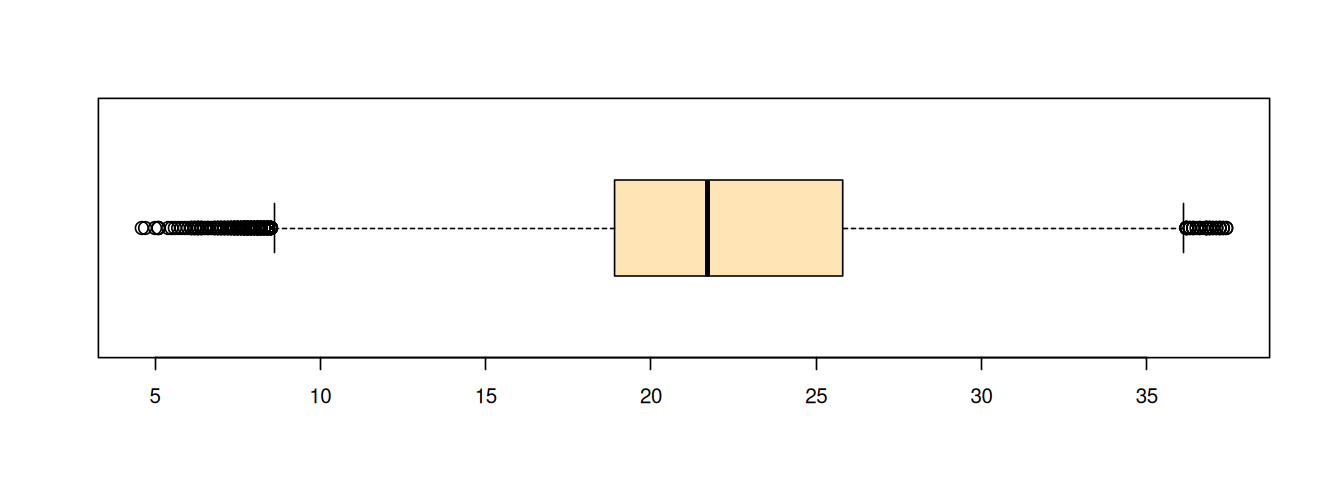

In [172]:
grafdim(11,4)
boxplot(df$temp, horizontal=TRUE, cex=1.3, col="moccasin")

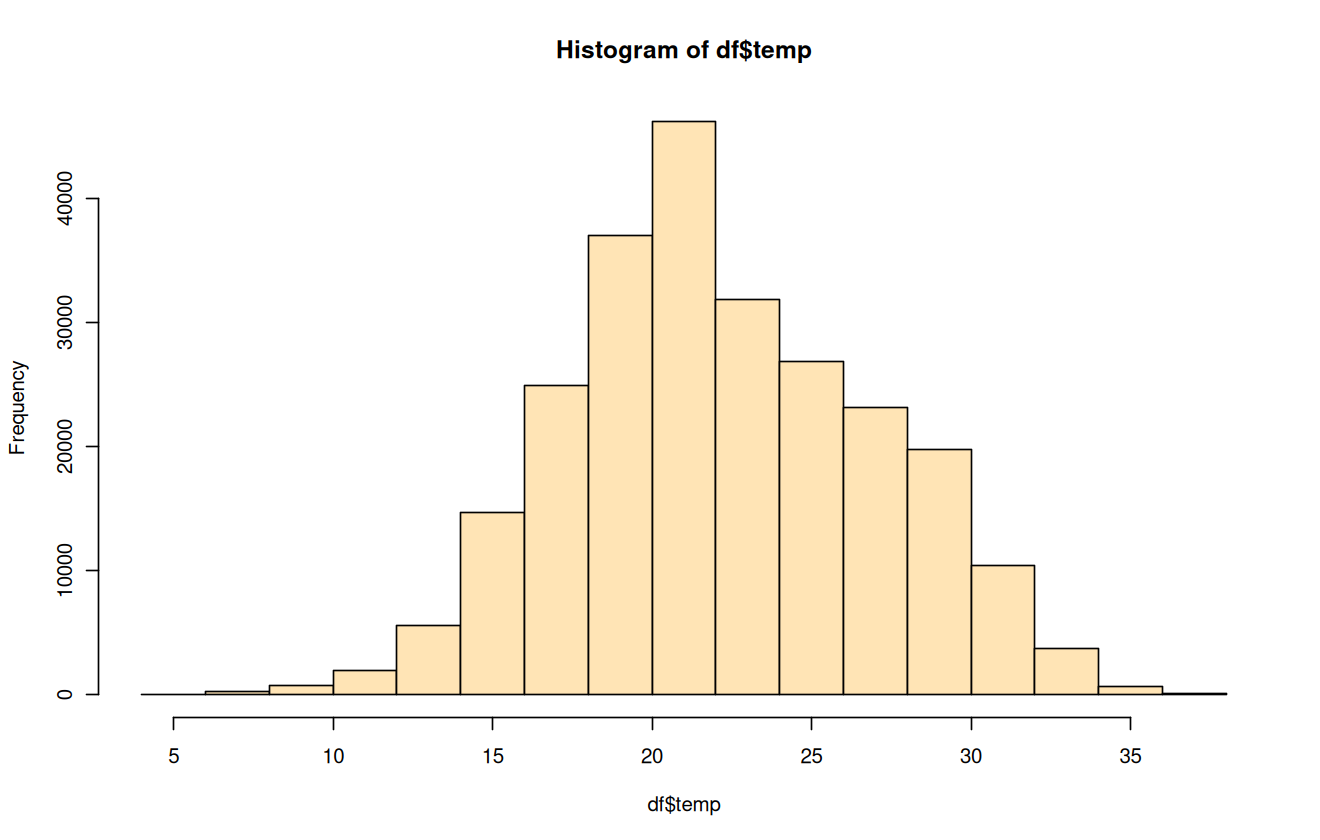

In [173]:
grafdim(11,7)
hist(df$temp, col="moccasin")

Como é o comportamento das temperaturas abaixo de 10 °C?

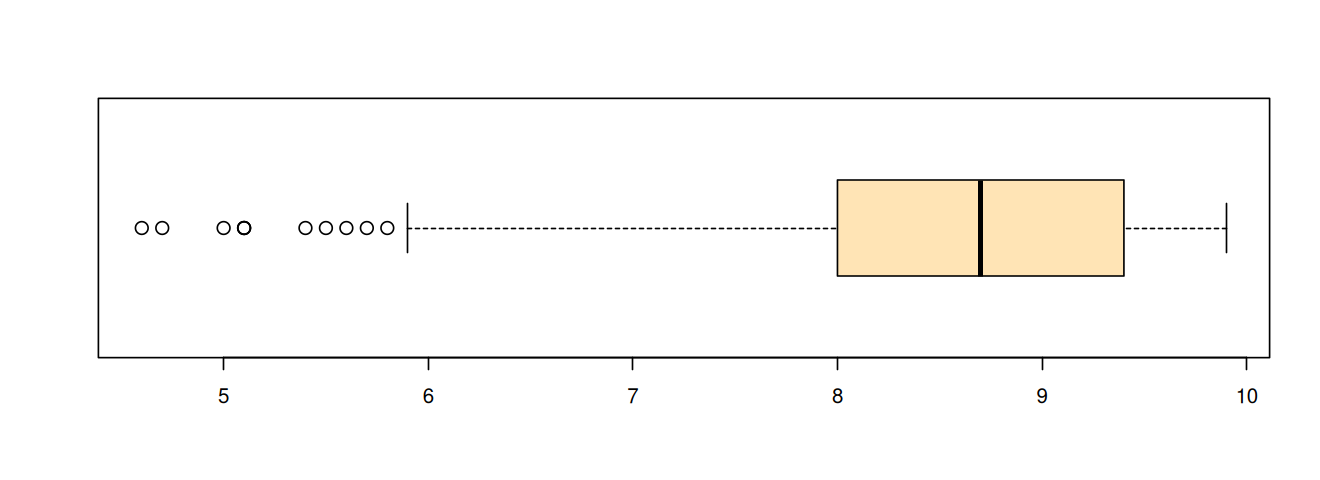

In [174]:
grafdim(11,4)
boxplot(df$temp[df$temp < 10], horizontal=TRUE, cex=1.3, col="moccasin")

In [175]:
print(df$temp[df$temp < 6])

 [1] 5.8 5.7 5.9 5.4 5.1 4.6 4.7 5.0 5.1 5.1 5.5 5.6


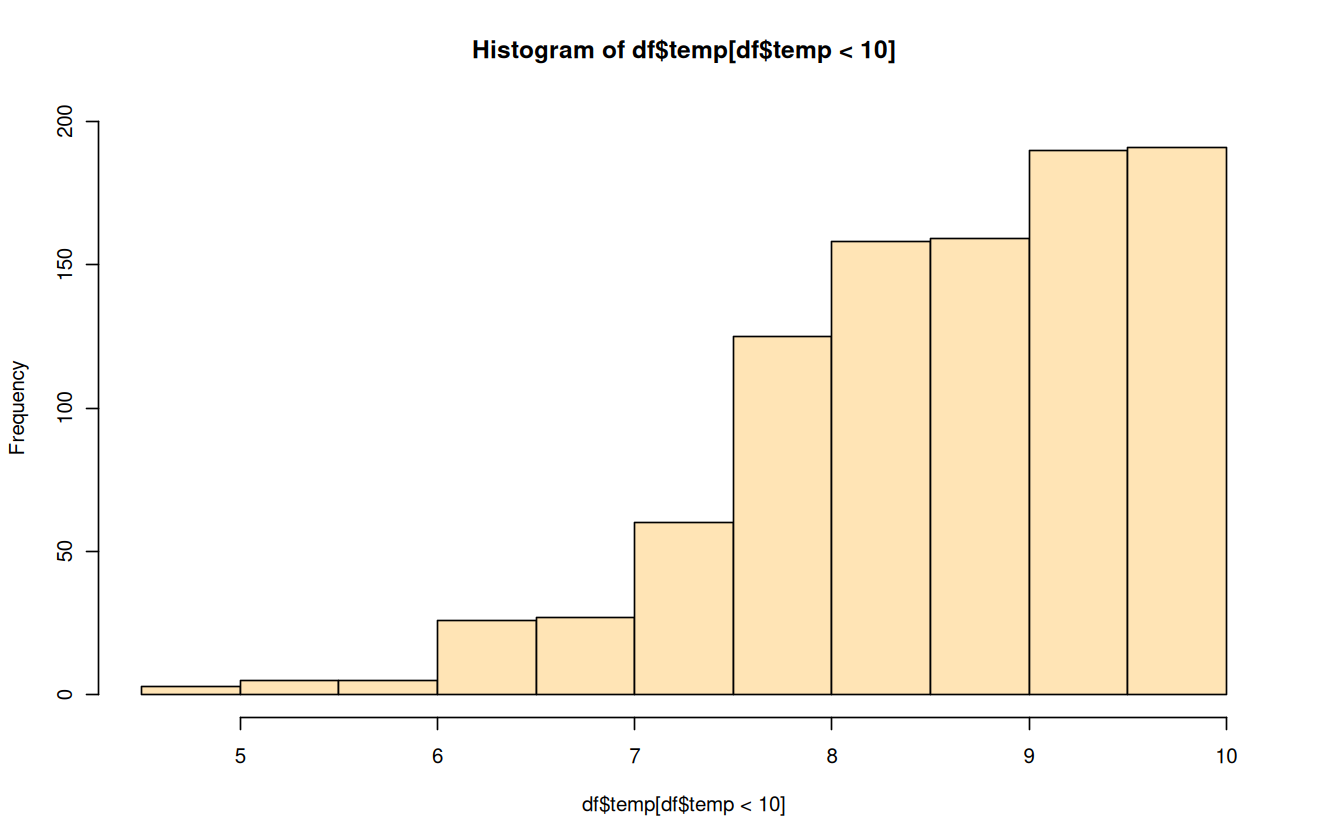

In [176]:
grafdim(11,7)
hist(df$temp[df$temp<10], col="moccasin", ylim=c(0,200))

Só por desencargo de consciência, quando essas temperaturas abaixo de 10°C ocorreram?

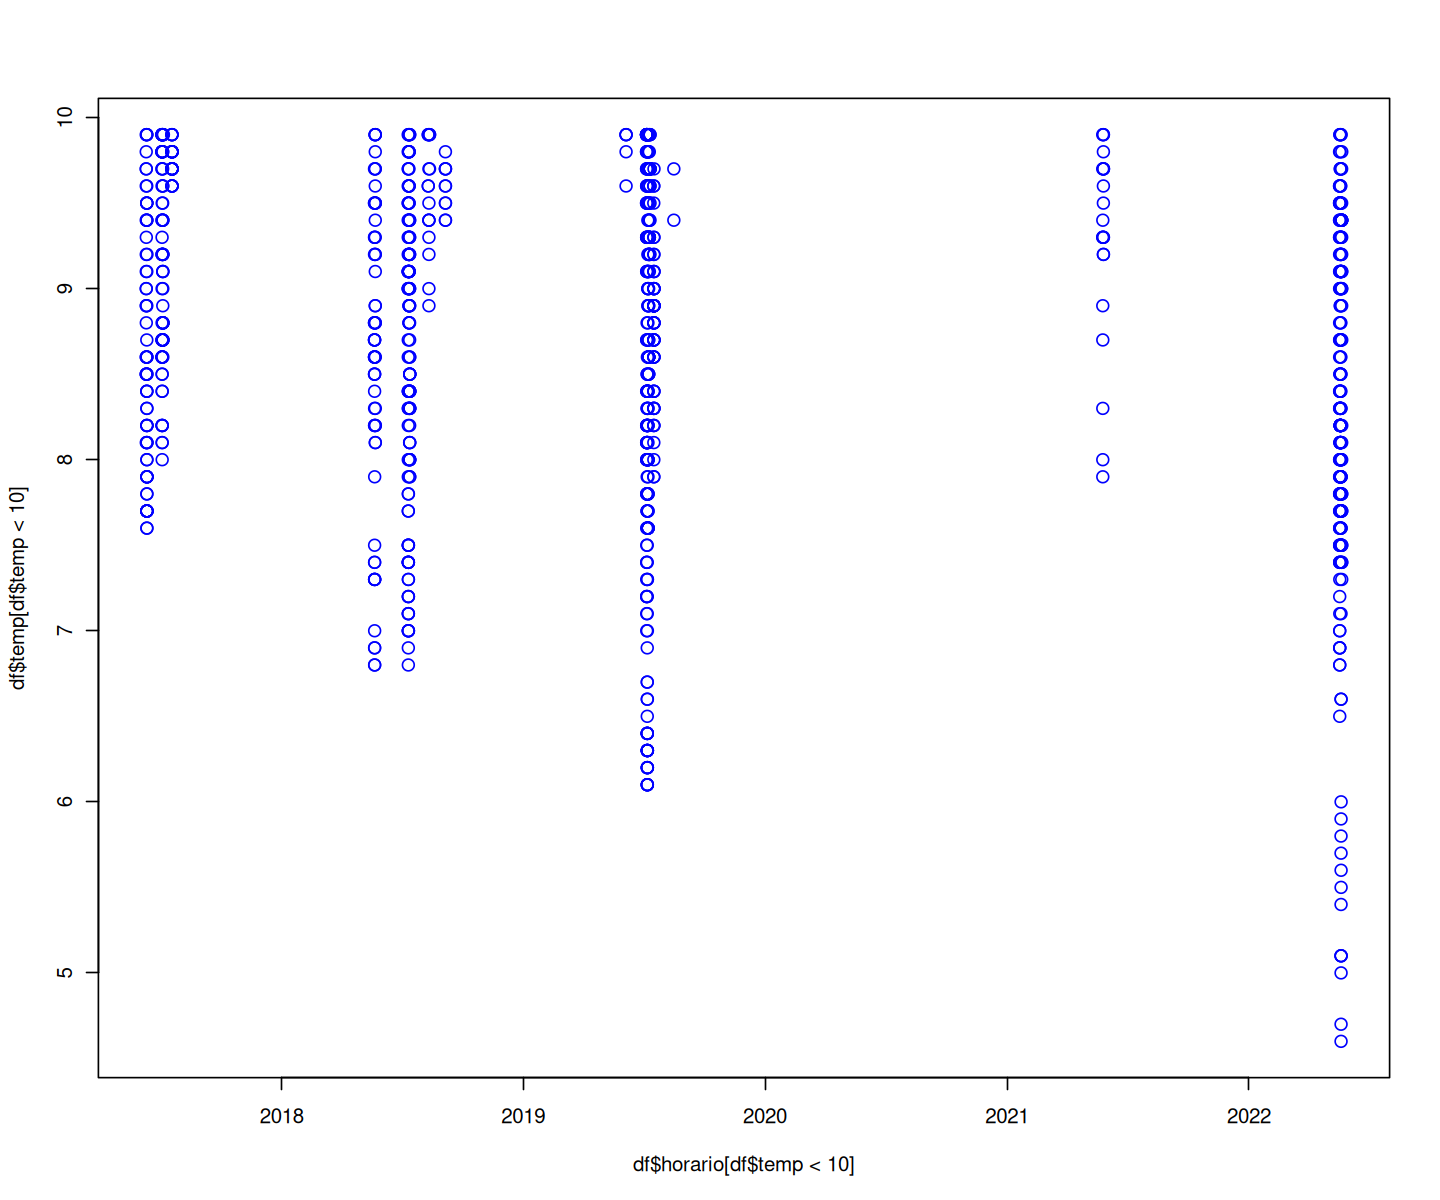

In [177]:
grafdim(12,10)
plot(df$horario[df$temp<10],df$temp[df$temp<10], col="blue", cex=1.2)

Parece inverno pra mim...

### Velocidade do vento

Mínimo em 0 km/h e máximo em 120 km/h.  
120 km/h? **Ops**.

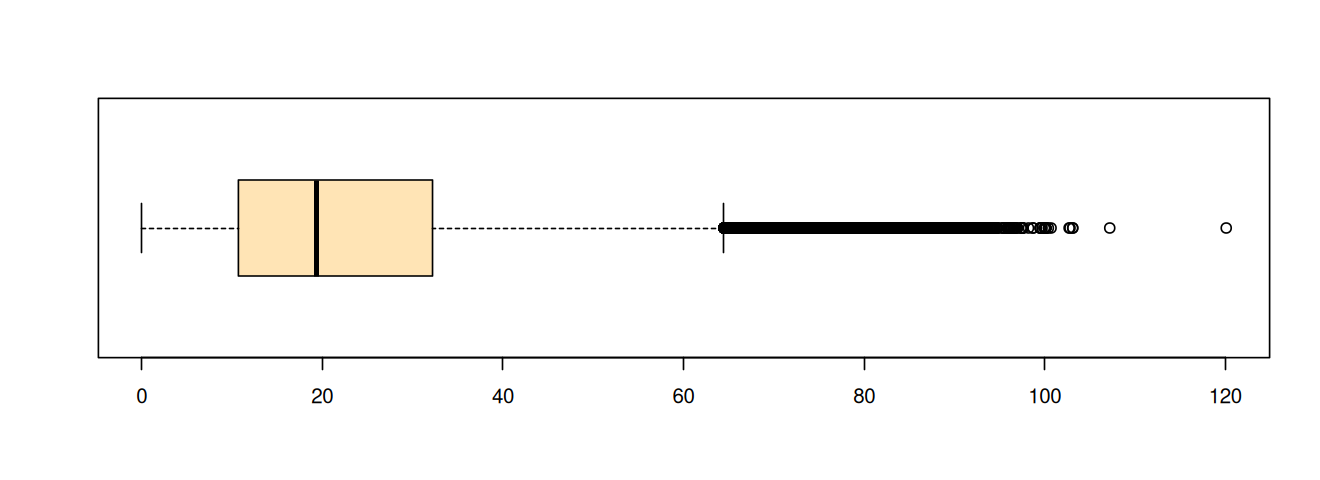

In [179]:
grafdim(11,4)
boxplot(df$vento, horizontal=TRUE, col="moccasin")

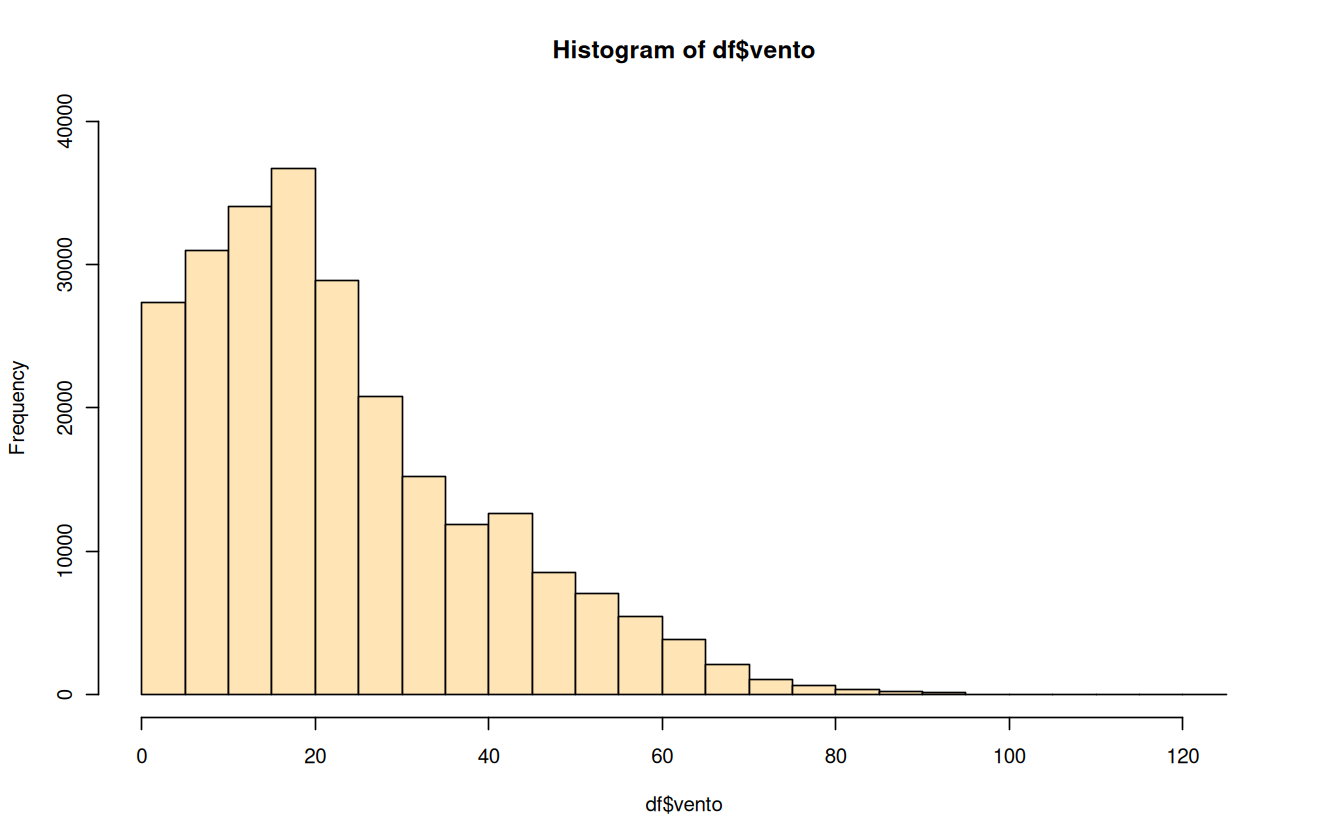

In [180]:
grafdim(11,7)
hist(df$vento, col="moccasin", ylim=c(0,40000))

Quando ocorreram esses ventos acima de 100 km/h?

In [181]:
# quais registros com vento acima de 100 km/h?
print(df[df$vento > 100,])

                   horario temp vento umid sensacao dia mes  ano hora min
121085 2019-04-28 18:20:00 20.9 107.2 81.4     19.7  28   4 2019   18  20
134873 2019-08-02 20:00:00 19.1 100.1 78.3     17.8   2   8 2019   20   0
136575 2019-08-14 15:40:00 17.1 100.1 66.8     15.5  14   8 2019   15  40
136576 2019-08-14 15:50:00 17.1 100.1 66.8     15.5  14   8 2019   15  50
136577 2019-08-14 16:00:00 17.1 100.1 66.8     15.5  14   8 2019   16   0
136578 2019-08-14 16:10:00 17.1 100.1 66.8     15.5  14   8 2019   16  10
136579 2019-08-14 16:20:00 17.1 100.1 66.8     15.5  14   8 2019   16  20
139745 2019-09-05 16:30:00 18.3 100.1 72.3     16.8   5   9 2019   16  30
139746 2019-09-05 16:40:00 18.3 100.1 72.3     16.8   5   9 2019   16  40
139760 2019-09-05 19:00:00 15.5 102.8 79.9     13.7   5   9 2019   19   0
139769 2019-09-05 20:30:00 15.3 100.4 81.2     13.4   5   9 2019   20  30
142236 2019-09-22 23:50:00 15.5 103.1 75.2     13.7  22   9 2019   23  50
142237 2019-09-23 00:00:00 15.5 103.1 

Todos os dias foram em 2019. O que teria acontecido entre abril e outubro de 2019?   
Pesquisar o que houve nesses dias, pois ventos de mais de 100 km/h causam grande destruição e, a partir 118 km/h já é considerado furacão.   
A propósito, nunca houve furacão em Campinas...

### Umidade do ar

Vamos ver como estão os valores registrados para a umidade do ar em Campinas:

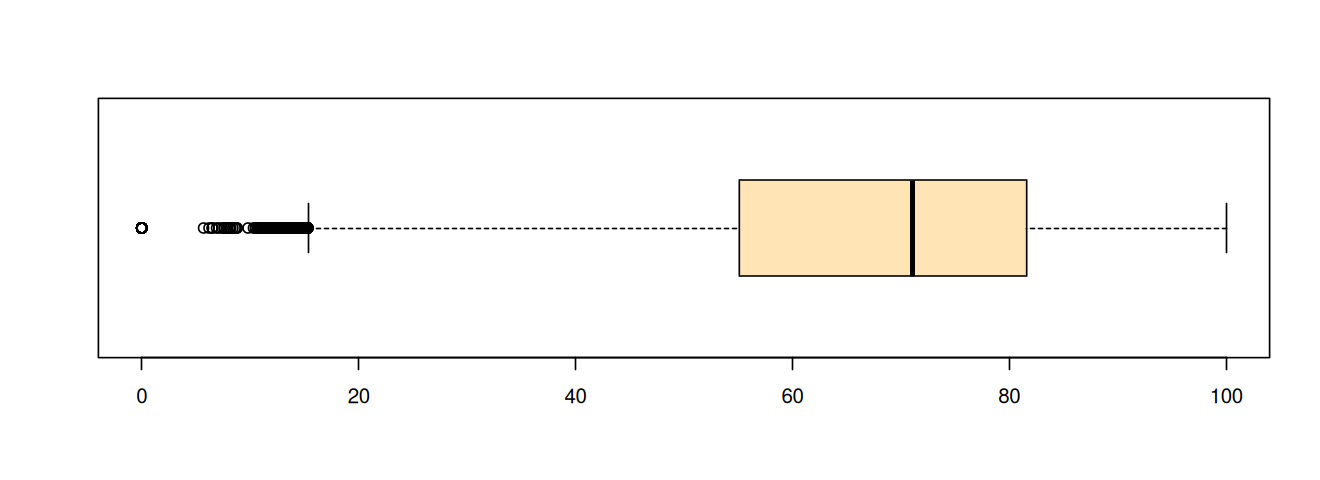

In [182]:
grafdim(11,4)
boxplot(df$umid, horizontal=TRUE, col="moccasin")

Hum. Abaixo de 20 é uma catástrofe, mas não é impossível. Impossível é 0.

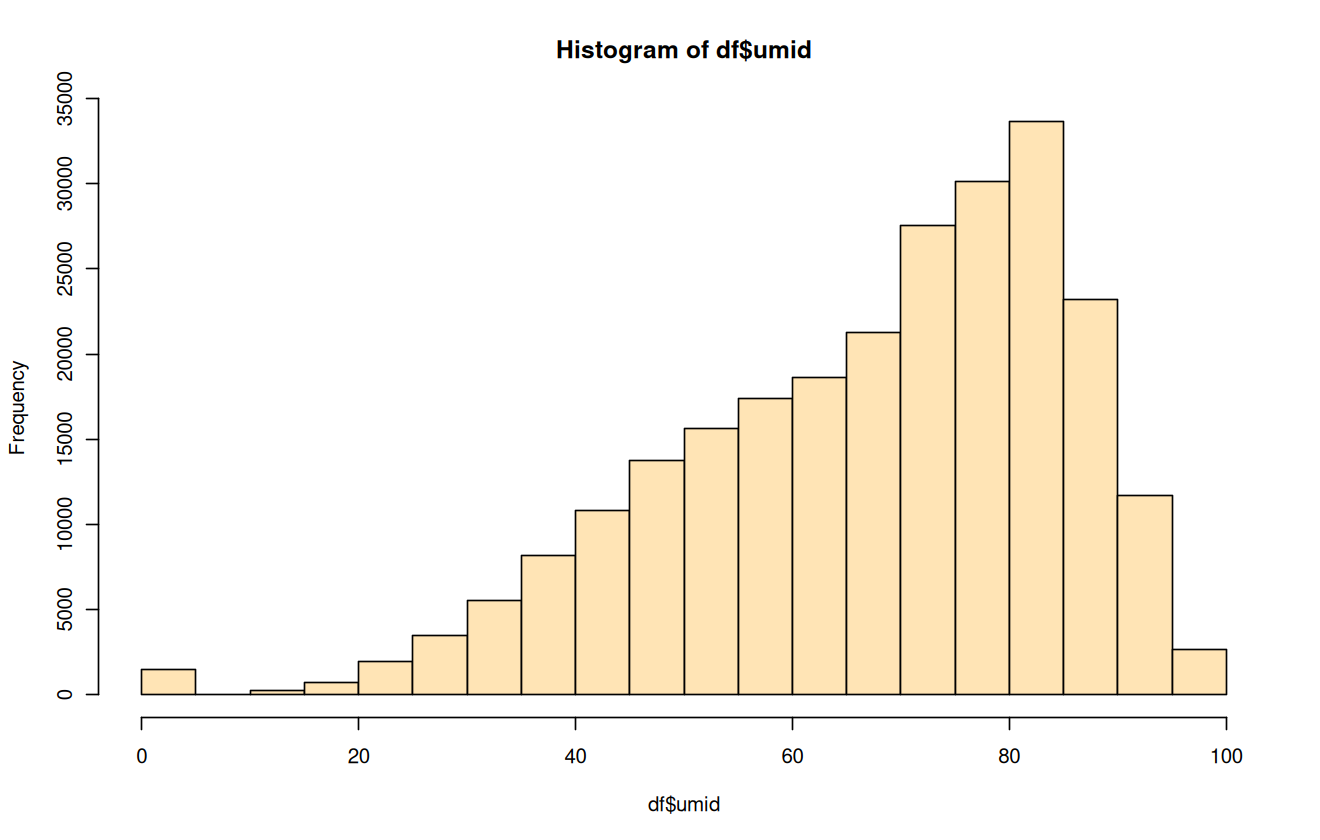

In [183]:
grafdim(11,7)
hist(df$umid, col="moccasin")

Vamos aumentar a resolução do histograma, para identificar com mais clareza o que ocorre abaixo de 10% de umidade:

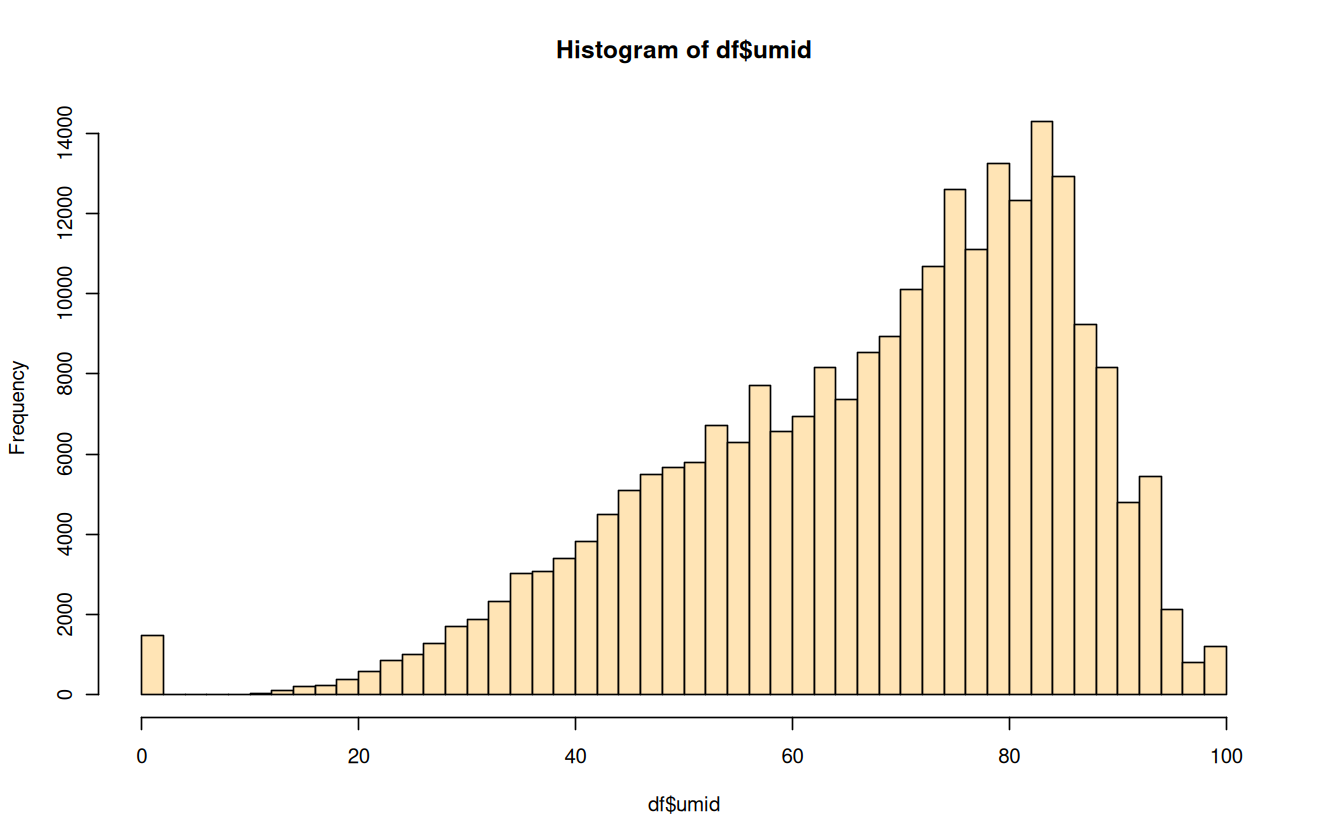

In [184]:
hist(df$umid, breaks=60, col="moccasin")

Tem uma grande quantidade de registros (aparentemente uns 1700) registrando 0% de umidade.   
É um problema, com certeza, pois _desertos_ tem em torno de 10% de umidade...

In [185]:
print(head(df[df$umid == 0, ]))

                   horario temp vento umid sensacao dia mes  ano hora min
104918 2019-01-05 07:00:00 20.6  17.0    0     19.4   5   1 2019    7   0
104919 2019-01-05 07:10:00 20.6  15.7    0     19.5   5   1 2019    7  10
104920 2019-01-05 07:20:00 20.6  15.7    0     19.5   5   1 2019    7  20
104921 2019-01-05 07:30:00 20.7  14.7    0     19.6   5   1 2019    7  30
104922 2019-01-05 07:40:00 20.8  15.2    0     19.6   5   1 2019    7  40
104923 2019-01-05 07:50:00 20.8  15.2    0     19.6   5   1 2019    7  50


Pois é, 2019 **e** 2020. 

Como se comportaram as medidas abaixo de 20% de umidade?

há 2386 registros abaixo de 20% de umidade

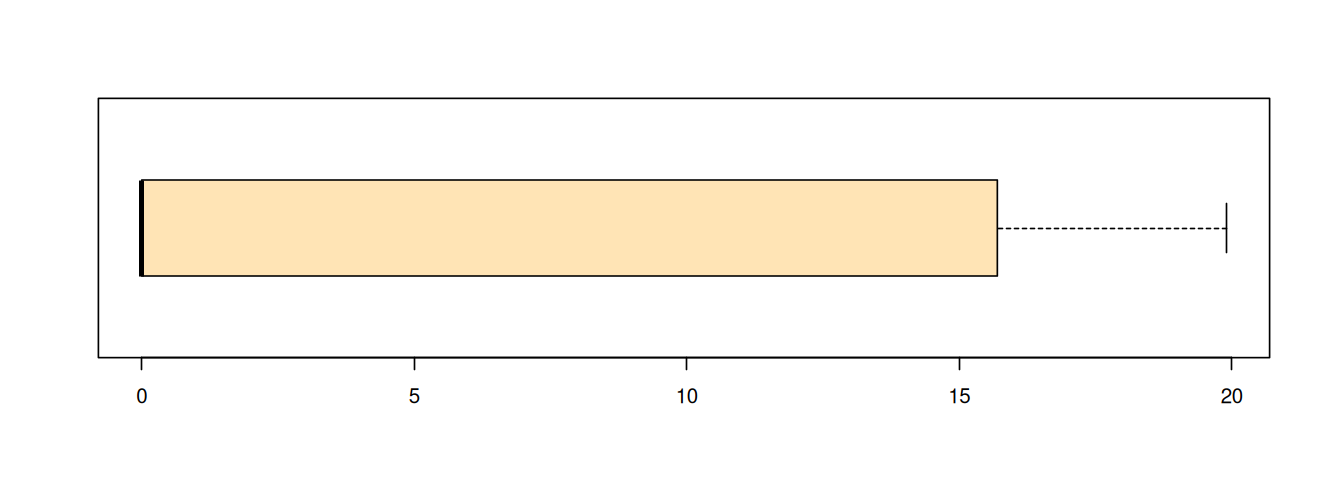

In [186]:
cat("há",length(df$umid[df$umid < 20]),"registros abaixo de 20% de umidade")
grafdim(11,4)
boxplot(df$umid[df$umid < 20], horizontal=TRUE, col="moccasin")

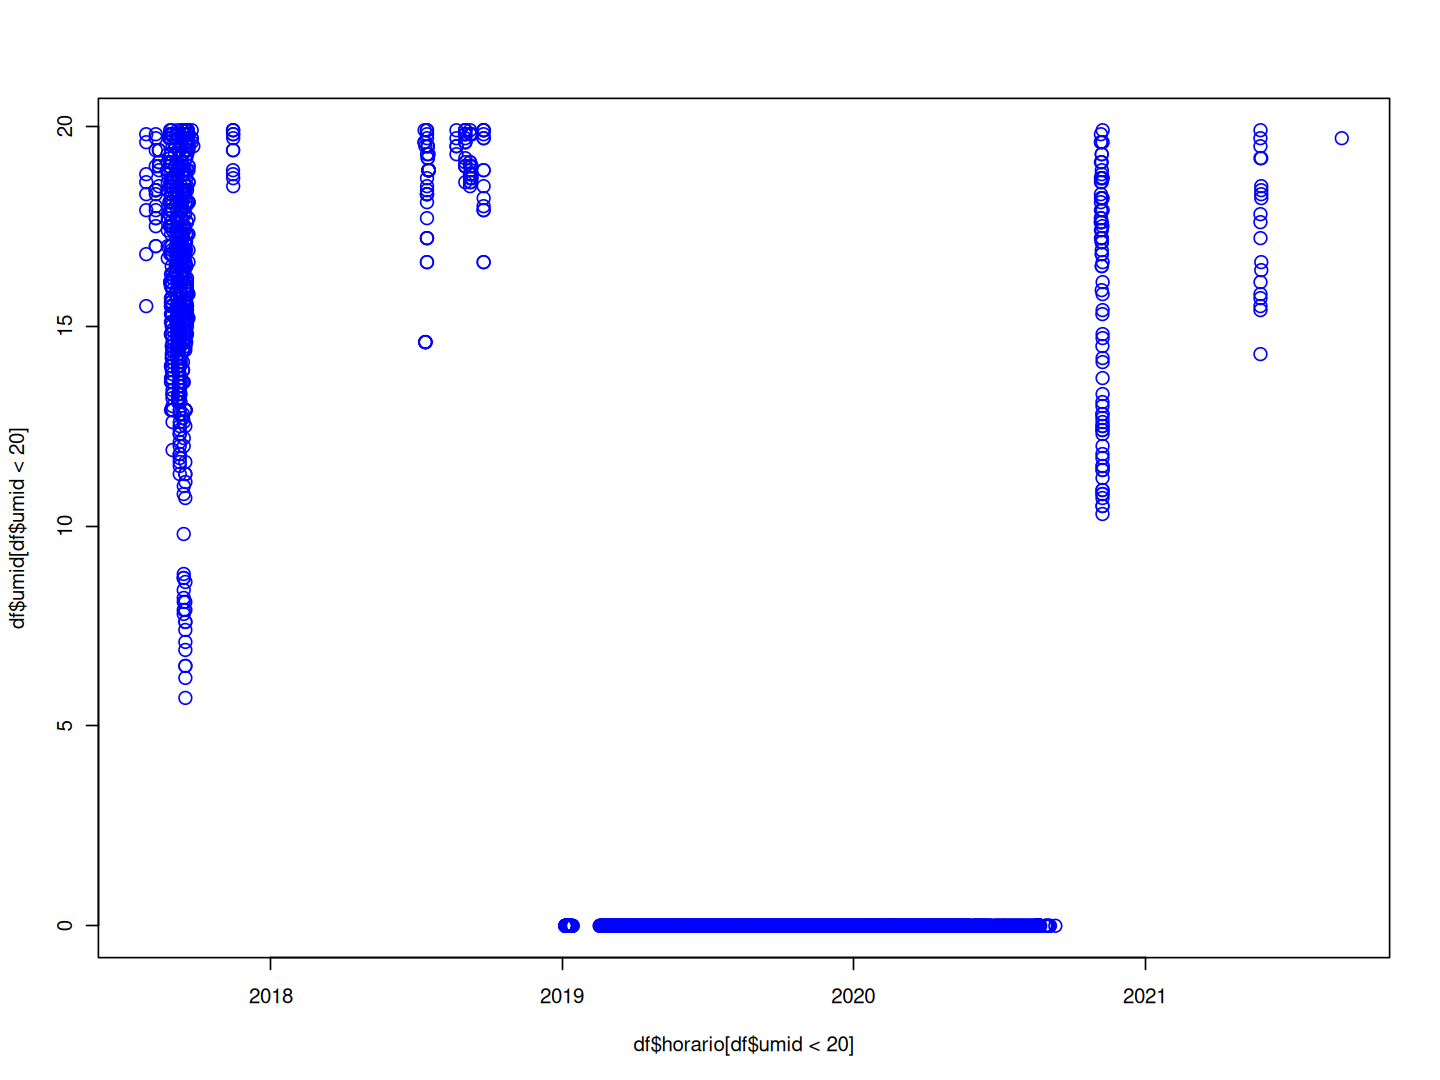

In [188]:
grafdim(12,9)
plot(df$horario[df$umid < 20], df$umid[df$umid < 20], cex=1.3, col="blue")

Como estão distribuídos esses registros com umidade abaixo de 20% de umidade?

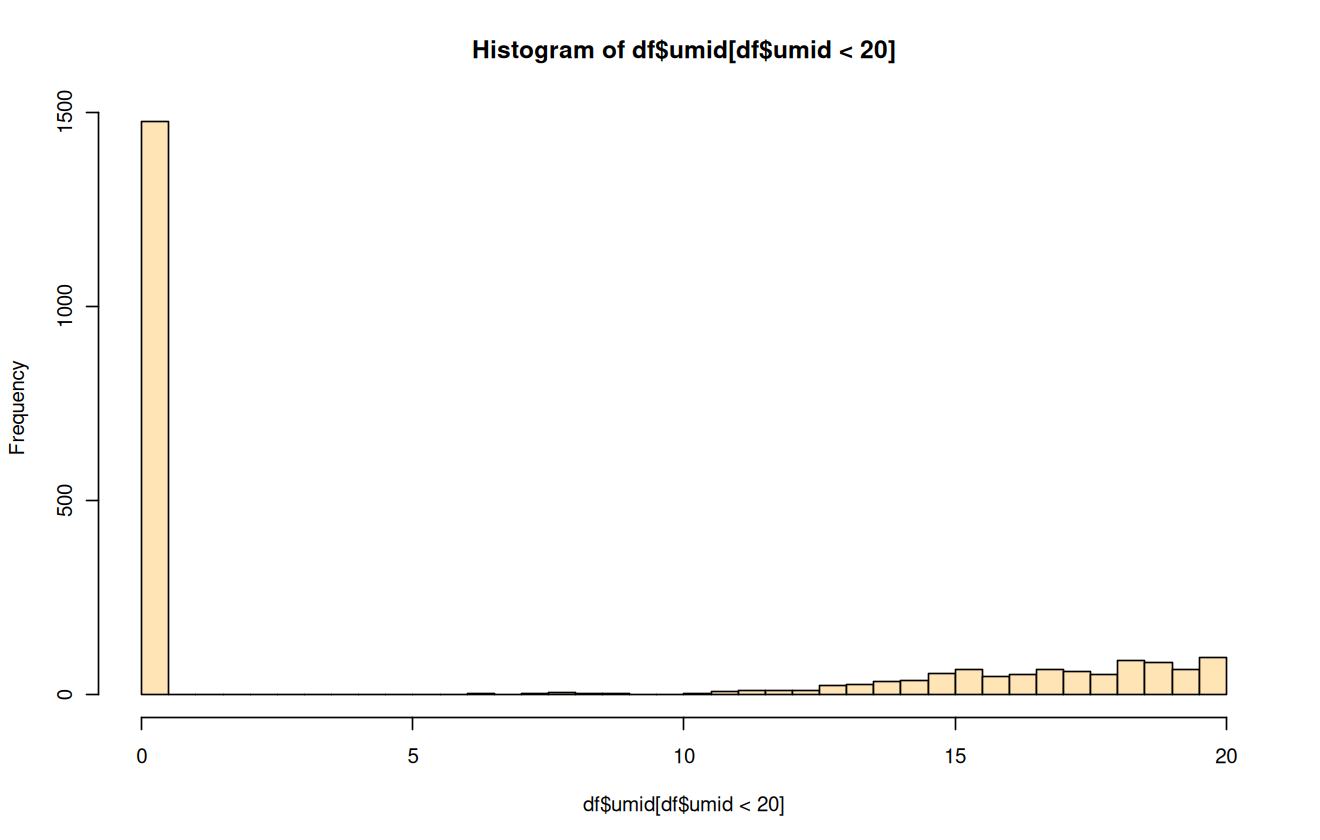

In [189]:
grafdim(11,7)
hist(df$umid[df$umid < 20], breaks=30, col="moccasin")

Registros em torno de 10% são ruins, aparentemente são raros e devem ser estudados.   
Observações com 0% são seguramente erros e convém que sejam eliminados.

Como se comportam as outras variáveis (ou _features_) para as observações em que a umidade é zero?

In [190]:
linhas <- df$umid == 0.0
cat("Há",sum(linhas),"com umidade zero")

Há 1476 com umidade zero

Vamos "fatiar" o conjunto de dados, construindo um outro apenas com os dados anômalos para umidade:

In [191]:
df_umid0 <- df[linhas,]

In [192]:
print(head(df_umid0))
print(tail(df_umid0))

                   horario temp vento umid sensacao dia mes  ano hora min
104918 2019-01-05 07:00:00 20.6  17.0    0     19.4   5   1 2019    7   0
104919 2019-01-05 07:10:00 20.6  15.7    0     19.5   5   1 2019    7  10
104920 2019-01-05 07:20:00 20.6  15.7    0     19.5   5   1 2019    7  20
104921 2019-01-05 07:30:00 20.7  14.7    0     19.6   5   1 2019    7  30
104922 2019-01-05 07:40:00 20.8  15.2    0     19.6   5   1 2019    7  40
104923 2019-01-05 07:50:00 20.8  15.2    0     19.6   5   1 2019    7  50
                   horario temp vento umid sensacao dia mes  ano hora min
190388 2020-08-30 16:50:00 21.5  47.8    0     20.2  30   8 2020   16  50
190532 2020-08-31 16:50:00 21.5  47.8    0     20.2  31   8 2020   16  50
190674 2020-09-01 16:50:00 21.5  47.8    0     20.2   1   9 2020   16  50
190818 2020-09-02 16:50:00 21.5  47.8    0     20.2   2   9 2020   16  50
190962 2020-09-03 16:50:00 21.5  47.8    0     20.2   3   9 2020   16  50
191935 2020-09-10 11:00:00 24.7  37.0 

Como estão as outras variáveis?

In [193]:
summary(df_umid0)

    horario                         temp           vento            umid  
 Min.   :2019-01-05 07:00:00   Min.   : 6.20   Min.   : 0.00   Min.   :0  
 1st Qu.:2019-08-01 07:07:30   1st Qu.:17.00   1st Qu.:15.60   1st Qu.:0  
 Median :2020-01-19 22:05:00   Median :20.20   Median :23.85   Median :0  
 Mean   :2019-12-15 02:27:48   Mean   :19.82   Mean   :27.43   Mean   :0  
 3rd Qu.:2020-04-18 13:07:30   3rd Qu.:22.00   3rd Qu.:36.10   3rd Qu.:0  
 Max.   :2020-09-10 11:00:00   Max.   :32.30   Max.   :81.80   Max.   :0  
                                                                          
    sensacao          dia           mes        ano           hora       
 Min.   : 2.10   19     :169   2      :260   2017:  0   Min.   : 0.000  
 1st Qu.:15.50   18     :102   8      :220   2018:  0   1st Qu.: 7.000  
 Median :19.00   21     :102   5      :172   2019:675   Median : 7.000  
 Mean   :18.39   23     : 91   1      :136   2020:801   Mean   : 8.128  
 3rd Qu.:20.90   20     : 71   3   

São basicamente 2019 e 2020. O mínimo é 5 de janeiro de 2019 e o máximo é 10 de setembro de 2020. 

Como se comportam uma contra as outras?

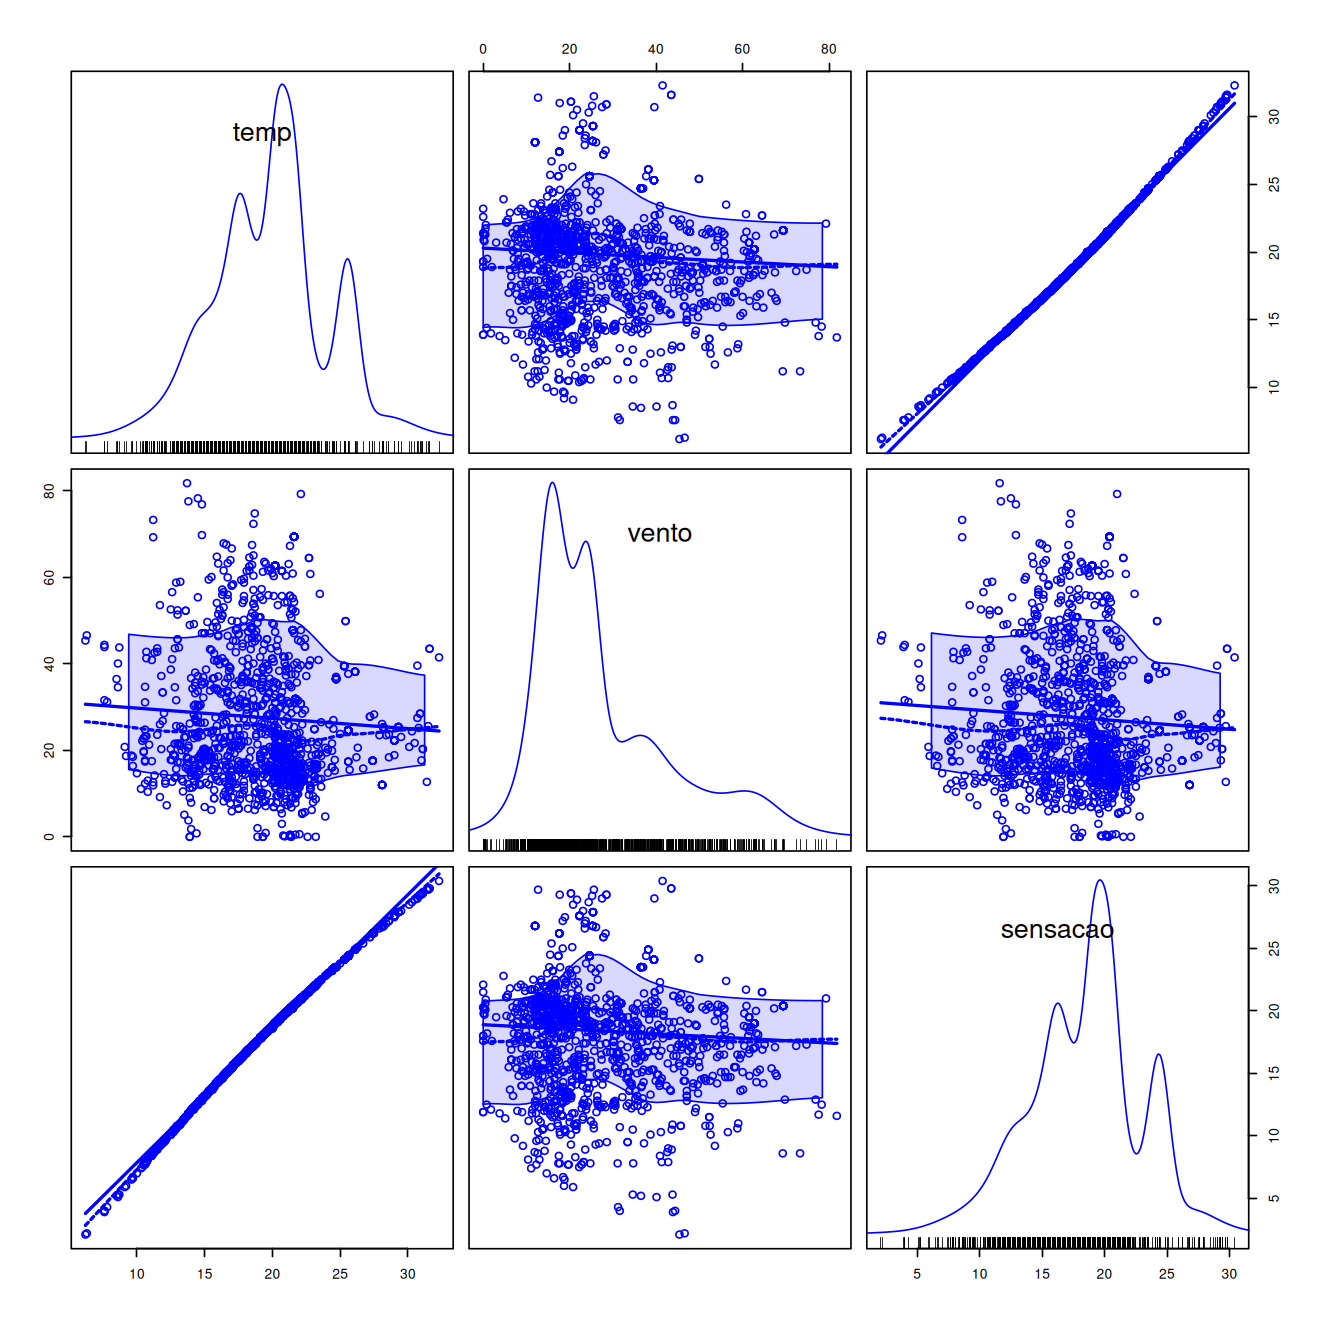

In [195]:
grafdim(11,11)
library(car)
scatterplotMatrix(df_umid0[,c("temp", "vento","sensacao")])

Os valores superficialmente não parecem apresentar problemas, apenas a umidade que é zero. Assim, o mais indicado seria perder (torná-los _perdido_ ou _not available_ `NA`) apenas os dados da umidade para essas observações no conjunto de dados (_dataset_) original.

In [196]:
df$umid[df$umid < 5] <- NA

In [197]:
summary(df)

    horario                         temp           vento       
 Min.   :2017-01-01 00:00:00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00   Max.   :37.40   Max.   :120.10  
                                                               
      umid           sensacao          dia              mes        
 Min.   :  5.70   Min.   :-0.20   21     :  8598   1      : 25713  
 1st Qu.: 55.50   1st Qu.:17.50   20     :  8470   3      : 25648  
 Median : 71.10   Median :20.50   8      :  8436   4      : 25085  
 Mean   : 67.69   Mean   :20.84   17     :  8405   5      : 24475  
 3rd Qu.: 81.60   3rd Qu.:24.60   9      :  8363   2      : 23115  
 Max.   :100.00   Max.   :99.90   6      :  8310   12     : 21770  
 NAs    :147

### Sensação térmica

Algo estranho nos valores da sensação térmica (`sensacao`)?   

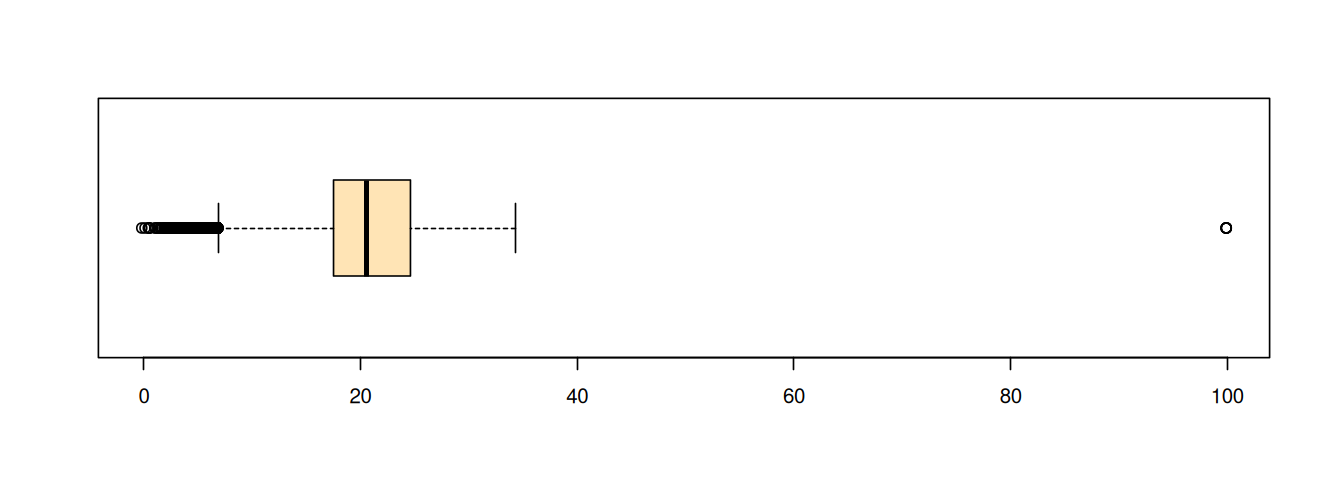

In [245]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$sensacao, horizontal=TRUE, col="moccasin")

Quantas vezes você ouviu "Está quente! A sensação térmica de hoje é 100°C" ...

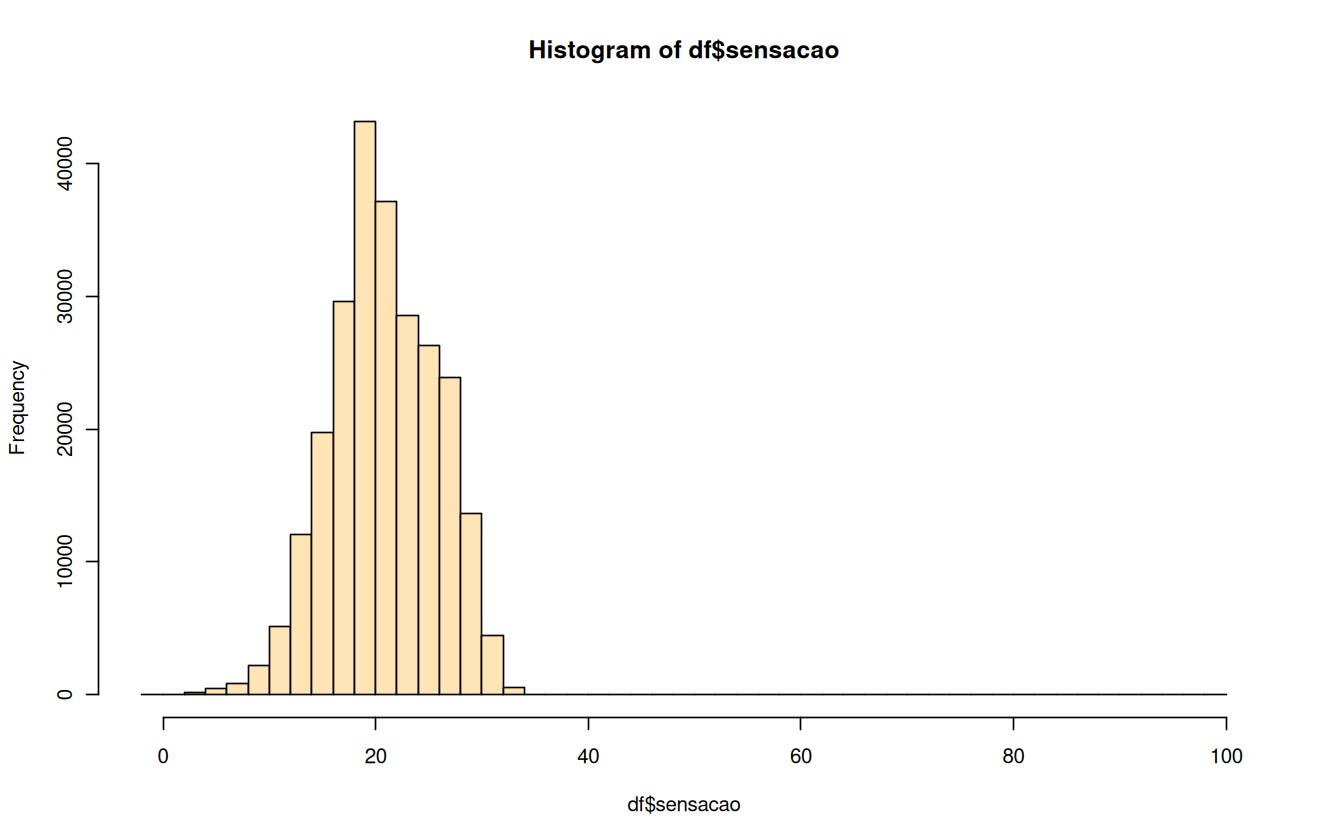

In [246]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$sensacao, breaks=50, col="moccasin")

A distribuição dos valores, diferentemente do caso da umidade, não são contínuos até 100°C. Aparentemente os casos com 100°C são isolados.

In [198]:
print(df[df$sensacao > 40,])

                  horario temp vento umid sensacao dia mes  ano hora min
87668 2018-09-07 07:10:00 13.4  37.0 75.3     99.9   7   9 2018    7  10
87812 2018-09-08 07:10:00 16.1  26.3 64.5     99.9   8   9 2018    7  10
87956 2018-09-09 07:10:00 15.1  28.1 75.8     99.9   9   9 2018    7  10
88100 2018-09-10 07:10:00 14.8  33.4 74.5     99.9  10   9 2018    7  10
88244 2018-09-11 07:10:00 15.4  34.7 76.2     99.9  11   9 2018    7  10


Interessante. Há cinco registros com sensação térmica de 99,9°C: são as medidas das 7h10 de 7 a 11 de setembro de 2018. Cinco dias em seguida, no mesmo horário, sendo o primeiro um feriado...

Como estão as medidas _vizinhas_? Vamos primeiro levantar os índices dos registros falhos:

In [199]:
# quais índices das linhas com problemas?
linhas <- which(df$sensacao == 99.9)
print(linhas)

[1] 86401 86545 86689 86833 86977


Para cada uma dos registros com sensação térmica de 99,9°C, vamos calcular a média dos 3 valores _anteriores_ com os 3 valores _seguintes_, sem o registro problemático:

In [202]:
for (x in linhas) {
    medidas <- df[(x-3):(x+3), "sensacao"] # desde três valores antes até três depois
    print("valores desde 3 antes até 3 depois")
    print(medidas)                   
    media   <- mean(medidas[-4])           # descarte o valor incorreto para calcular a média
    print(paste("média dos 3 anteriores com 3 seguintes:",round(media,3)))
}

[1] "valores desde 3 antes até 3 depois"
[1] 10.3 10.6 10.6 99.9 11.7 12.1 12.4
[1] "média dos 3 anteriores com 3 seguintes: 11.283"
[1] "valores desde 3 antes até 3 depois"
[1] 13.4 13.7 13.9 99.9 14.9 15.5 16.1
[1] "média dos 3 anteriores com 3 seguintes: 14.583"
[1] "valores desde 3 antes até 3 depois"
[1] 12.7 12.8 13.0 99.9 13.4 13.6 13.9
[1] "média dos 3 anteriores com 3 seguintes: 13.233"
[1] "valores desde 3 antes até 3 depois"
[1] 12.0 12.3 12.5 99.9 13.2 13.6 14.1
[1] "média dos 3 anteriores com 3 seguintes: 12.95"
[1] "valores desde 3 antes até 3 depois"
[1] 12.9 13.0 13.3 99.9 14.0 14.4 14.8
[1] "média dos 3 anteriores com 3 seguintes: 13.733"


Aparentemente ocorreu um erro de medição _precisamente_ às 7h10 desses dias. As medidas tomadas antes e depois do horário estão boas. Uma saída seria descartar o valor problemático substituindo-o pela média dos seus vizinhos.

In [204]:
for (x in linhas) {
    medidas <- df[(x-3):(x+3), "sensacao"]  # 
    media   <- mean(medidas[-4])
    df[x, "sensacao"] <- media
}

Vamos ver como ficaram os valores problemáticos ajustados pela média dos vizinhos:

In [205]:
print(df[linhas,])

                  horario temp vento umid sensacao dia mes  ano hora min
87668 2018-09-07 07:10:00 13.4  37.0 75.3 11.28333   7   9 2018    7  10
87812 2018-09-08 07:10:00 16.1  26.3 64.5 14.58333   8   9 2018    7  10
87956 2018-09-09 07:10:00 15.1  28.1 75.8 13.23333   9   9 2018    7  10
88100 2018-09-10 07:10:00 14.8  33.4 74.5 12.95000  10   9 2018    7  10
88244 2018-09-11 07:10:00 15.4  34.7 76.2 13.73333  11   9 2018    7  10


Parecem normais. Vamos ver como ficou no geral:

In [207]:
summary(df)

    horario                         temp           vento       
 Min.   :2017-01-01 00:00:00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00   Max.   :37.40   Max.   :120.10  
                                                               
      umid           sensacao          dia              mes        
 Min.   :  5.70   Min.   :-0.20   21     :  8598   1      : 25713  
 1st Qu.: 55.50   1st Qu.:17.50   20     :  8470   3      : 25648  
 Median : 71.10   Median :20.50   8      :  8436   4      : 25085  
 Mean   : 67.69   Mean   :20.83   17     :  8405   5      : 24475  
 3rd Qu.: 81.60   3rd Qu.:24.60   9      :  8363   2      : 23115  
 Max.   :100.00   Max.   :34.30   6      :  8310   12     : 21770  
 NAs    :147

Agora está pronto para ser salvo para análise.
É interessante manter um banco de dados de cada etapa para compartimentalizar o processo: se houver algum problema em um passo posterior, basta voltar um passo, corrigir/atualizar o _dataset_ e refazer o passo.

In [208]:
cepagri_01 <- df

In [209]:
save(cepagri_01, grafdim, file="dad/cepagri_01_variaveis.RData")

## Carga